# Imports

In [1]:
# ---- Device: must run before anything imports jax ----
from devices import use_device
use_device("auto")      # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
import jax, numpyro
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print(jax.default_backend())   # 'gpu' or 'cpu': where JAX runs things by default
print(jax.devices())           # e.g. [CudaDevice(id=0)] for the GPU, or 8 CpuDevices
print("local device count:", jax.local_device_count())

import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value

from likelihood import (
    FD_gaussianlikelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
    wraparound_ratio_posthoc,
)
from model import (
    setup_model,
    make_orthogonal_poly_log_sed,
)
from data import (
    prepare_burst,
)
from run import (
    set_priors,
    run_fit,
    posthoc_samples,
)
from results import (
    save_run,
    to_idata,
)

from plotting import (
    plot_burst_TD, 
    plot_burst_FD,
    model_from_draw,
    plot_fit_TD,
    plot_fit_FD,
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import arviz as az
import arviz_plots as azp
az.rcParams["plot.max_subplots"] = 300

import random

FRBayes: running on the GPU


/arc/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.2
gpu
[CudaDevice(id=0)]
local device count: 1


# Setup

In [2]:
from pathlib import Path

PROJECT  = Path("/arc/home/hsiegel/FRBayes")

event_id = "22310619_BB" #Multi-pulse, 3 pulses
data_path = PROJECT / "data" / f"event_{event_id}.npz"
"22310619_BB"
burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=8,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# event_id = "27687783_BB" #Multi-pulse, many
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=64,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "23438043_BB" # Single-pulse, Narrow SED with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "22154974_BB" # Single-pulse, Broadband with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

806 good channels -> 50 blocks of 16 (6 dropped); block span median 6.641 MHz, max 37.109 MHz
noise estimated from 171 of 858 time bins (first 20% of the segment)
Fourier truncation: keeping 52 of 430 bins (up to 5.9 kHz of 48.8 kHz)
weighted mean frequency 592.4 MHz, reference frequency 563.1 MHz


In [3]:
burst.data_fd.shape

(50, 52)

rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


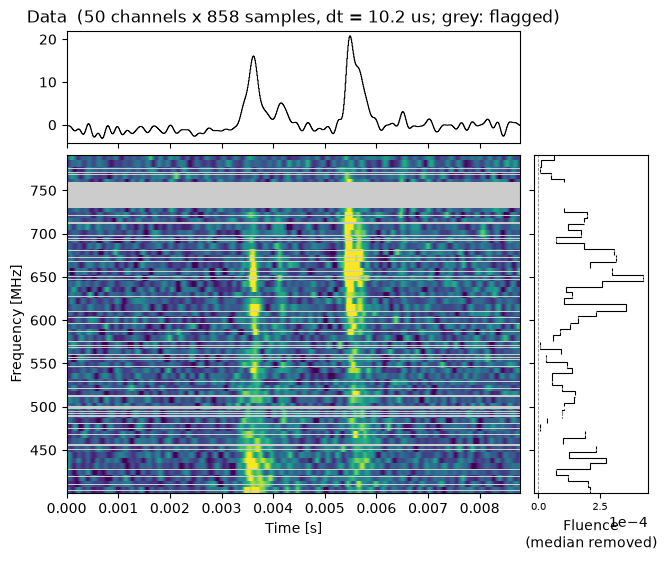

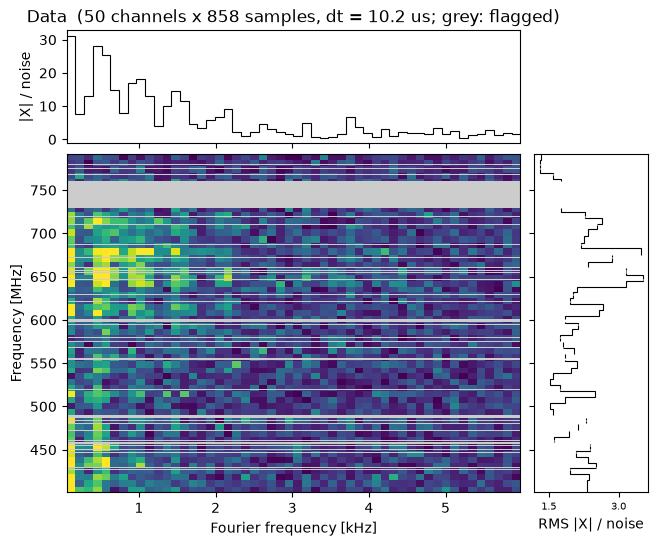

In [4]:
# M_FD = jnp.sum(jax.vmap(single_pulse_fn)(params), axis=0)    # (n_chan, n_fourier)

plot_burst_TD(burst);                                          # data, in time
# plot_burst_TD(burst, M_FD, title="Model")                     # model, in time
plot_burst_FD(burst);                                          # data, in Fourier space
# plot_burst_FD(burst, burst.data_fd - M_FD, title="Residual")  # residual, in Fourier space

# Run

In [6]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

n_pulses = 5
num_chains = 32
# n_pulses = 2
# num_chains = 8


target_accept_prob = 0.8
seed = 2
num_warmup = 500
num_samples = 200
progress_bar = True
repulsion_dict = {}
# repulsion_dict={"tau_scale":1, "x_min":1}


priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0)
# priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, delta=dist.Uniform(-5.0, -3.0))
# priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, gamma_range=(-10.0, 30.0), beta_range=(-10.0, 30.0))


extend_duration = False # Padding against wraparound: off by default. Turn on when a pulse reaches the window edge.
fit_fn = single_pulse_fn.extend_model_duration(burst, priors) if extend_duration else single_pulse_fn

mcmc = run_fit(burst, fit_fn, priors, FD_gaussianlikelihood, seed=seed,
               num_chains=num_chains, n_pulses=n_pulses, target_accept_prob=target_accept_prob,
               num_warmup=num_warmup, num_samples=num_samples, progress_bar=progress_bar,
               repulsion=repulsion_dict)#, shared_params=("DM", "tau_ref", "delta"))
samples = mcmc.get_samples()

mcmc_data = to_idata(mcmc, log_likelihood={}, posterior_predictive={})
# idata = save_run(None, mcmc, burst, priors, data_path,
#                  single_pulse_fn=fit_fn, extra_samples=extra, event_id=event_id)

prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011637152739660515
prior being set with bounds:
c1_min = -1.9209627 
c1_max = 38.41925 
c2_min = -5.038574 
c2_max = 0.25192872
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: Uniform(low=2.68908e-05, high=0.000292864)
tau_ref: Uniform(low=0, high=0.00116372)
c1: Uniform(low=-1.92096, high=38.4193)
c2: Uniform(low=-5.03857, high=0.251929)
A_snr: HalfNormal(scale=100)
run_fit seed: 2
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [04:23<00:00,  2.66it/s]


sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


In [7]:
div = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["diverging"]).astype(bool)   # (chain, draw)
print("divergences per chain:", div.sum(axis=1))
# s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
# snr_on = 3.0                                                       # whatever you used
# checks = {
#     "closest-pair x":         s["toa_separation"].min(axis=-1),
#     "smallest A_snr":         s["A_snr"].min(axis=-1),
#     "pulse near snr_on (frac)": (np.abs(s["A_snr"] - snr_on) < 1.0).any(axis=-1).astype(float),
# }
# for name, v in checks.items():
#     print(f"{name:25s} divergent: {np.median(v[div]) if 'frac' not in name else v[div].mean():.2f}   "
#           f"others: {np.median(v[~div]) if 'frac' not in name else v[~div].mean():.2f}")

divergences per chain: [ 0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  1  0  0  0  5  0  0  0
 64  0  0  0  0 16  0  0]


In [8]:
steps = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])     # (chain, draw), after warmup
depth = np.ceil(np.log2(steps + 1)).astype(int)
max_depth = 10                                                                    # whatever the run used
for c in range(steps.shape[0]):
    print(f"chain {c}: median depth {np.median(depth[c]):.0f}   max {depth[c].max()}   "
          f"hit the limit {np.mean(steps[c] >= 2 ** max_depth - 1):.0%}   mean steps {steps[c].mean():.0f}")

chain 0: median depth 6   max 8   hit the limit 0%   mean steps 91
chain 1: median depth 6   max 7   hit the limit 0%   mean steps 56
chain 2: median depth 7   max 8   hit the limit 0%   mean steps 122
chain 3: median depth 5   max 6   hit the limit 0%   mean steps 32
chain 4: median depth 5   max 5   hit the limit 0%   mean steps 29
chain 5: median depth 6   max 8   hit the limit 0%   mean steps 83
chain 6: median depth 5   max 6   hit the limit 0%   mean steps 30
chain 7: median depth 4   max 6   hit the limit 0%   mean steps 19
chain 8: median depth 4   max 5   hit the limit 0%   mean steps 20
chain 9: median depth 5   max 5   hit the limit 0%   mean steps 28
chain 10: median depth 5   max 6   hit the limit 0%   mean steps 26
chain 11: median depth 5   max 6   hit the limit 0%   mean steps 29
chain 12: median depth 8   max 8   hit the limit 0%   mean steps 198
chain 13: median depth 8   max 8   hit the limit 0%   mean steps 254
chain 14: median depth 5   max 7   hit the limit 0%   m

In [9]:
ns = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])
print("leapfrogs per iteration, median per chain:", np.median(ns, axis=1), "  max:", ns.max())
print("step size per chain:", np.asarray(mcmc.last_state.adapt_state.step_size))

leapfrogs per iteration, median per chain: [ 63.   63.  127.   31.   31.   63.   31.   15.   15.   31.   31.   31.
 255.  255.   31.  255.   63.   31.   15.   31.   63.   31.   15.  127.
  99.5  31.   31.   31.   31.   63.   15.   15. ]   max: 255
step size per chain: [0.04596792 0.08105629 0.03758984 0.12871256 0.15598144 0.05720394
 0.13375434 0.22708641 0.2101404  0.1543089  0.1780092  0.16282442
 0.02209097 0.01048856 0.12832718 0.00468789 0.07147617 0.19043446
 0.21052256 0.1630353  0.06117598 0.19265269 0.21080323 0.02243248
 0.03398323 0.1872963  0.17416838 0.18577653 0.13067739 0.05359133
 0.20656821 0.2135966 ]


In [10]:
ex = mcmc.get_extra_fields(group_by_chain=True)
pe, ns = np.asarray(ex["potential_energy"]), np.asarray(ex["num_steps"])
eps = np.asarray(mcmc.last_state.adapt_state.step_size)
s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
A = s["A_snr"]; active = A > 3.0
j, k = np.triu_indices(A.shape[-1], k=1)
x_close = np.where(active[..., j] & active[..., k], s["toa_separation"], np.inf).min(-1)  # closest active pair
half_on = ((A > 0.5) & (A < 3.0)).sum(-1)                  # pulses at the on/off gate: funnel necks
for c in np.argsort(pe.mean(axis=1)):
    print(f"chain {c:2d}: -log post {pe[c].mean():8.1f}  step {eps[c]:.4f}  leapfrogs {np.median(ns[c]):4.0f}  "
          f"active {active[c].sum(-1).mean():4.1f}  closest x {np.median(x_close[c]):5.2f}  half-on {half_on[c].mean():.1f}")

chain  9: -log post   3693.8  step 0.1543  leapfrogs   31  active  4.4  closest x  1.12  half-on 0.6
chain  2: -log post   3758.9  step 0.0376  leapfrogs  127  active  5.0  closest x  1.15  half-on 0.0
chain  4: -log post   3759.1  step 0.1560  leapfrogs   31  active  5.0  closest x  1.16  half-on 0.0
chain  6: -log post   3759.2  step 0.1338  leapfrogs   31  active  5.0  closest x  1.15  half-on 0.0
chain 19: -log post   3773.6  step 0.1630  leapfrogs   31  active  4.6  closest x  1.16  half-on 0.4
chain 10: -log post   3773.6  step 0.1780  leapfrogs   31  active  4.5  closest x  1.16  half-on 0.5
chain 14: -log post   3774.0  step 0.1283  leapfrogs   31  active  4.6  closest x  1.16  half-on 0.4
chain 29: -log post   3779.8  step 0.0536  leapfrogs   63  active  4.5  closest x  1.16  half-on 0.5
chain 30: -log post   3780.0  step 0.2066  leapfrogs   15  active  4.5  closest x  1.16  half-on 0.5
chain 22: -log post   3780.1  step 0.2108  leapfrogs   15  active  4.5  closest x  1.15  ha

In [11]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,35.837,41.858,3.816,0.000,0.000
A[1],0.000,0.000,0.000,0.000,37.734,48.587,2.949,0.000,0.000
A[2],0.000,0.000,0.000,0.000,37.842,44.625,2.935,0.000,0.000
A[3],0.000,0.000,0.000,0.000,37.649,39.665,4.040,0.000,0.000
A[4],0.000,0.000,0.000,0.000,38.554,43.225,2.741,0.000,0.000
...,...,...,...,...,...,...,...,...,...
toa_separation[5],4.764,3.629,1.173,11.934,35.264,37.854,4.370,0.598,0.569
toa_separation[6],4.695,2.923,2.264,10.824,42.100,47.792,2.239,0.465,0.575
toa_separation[7],5.164,4.042,0.790,12.656,35.773,40.039,3.886,0.664,0.578
toa_separation[8],6.818,4.938,1.918,15.388,37.031,44.471,3.189,0.777,0.538


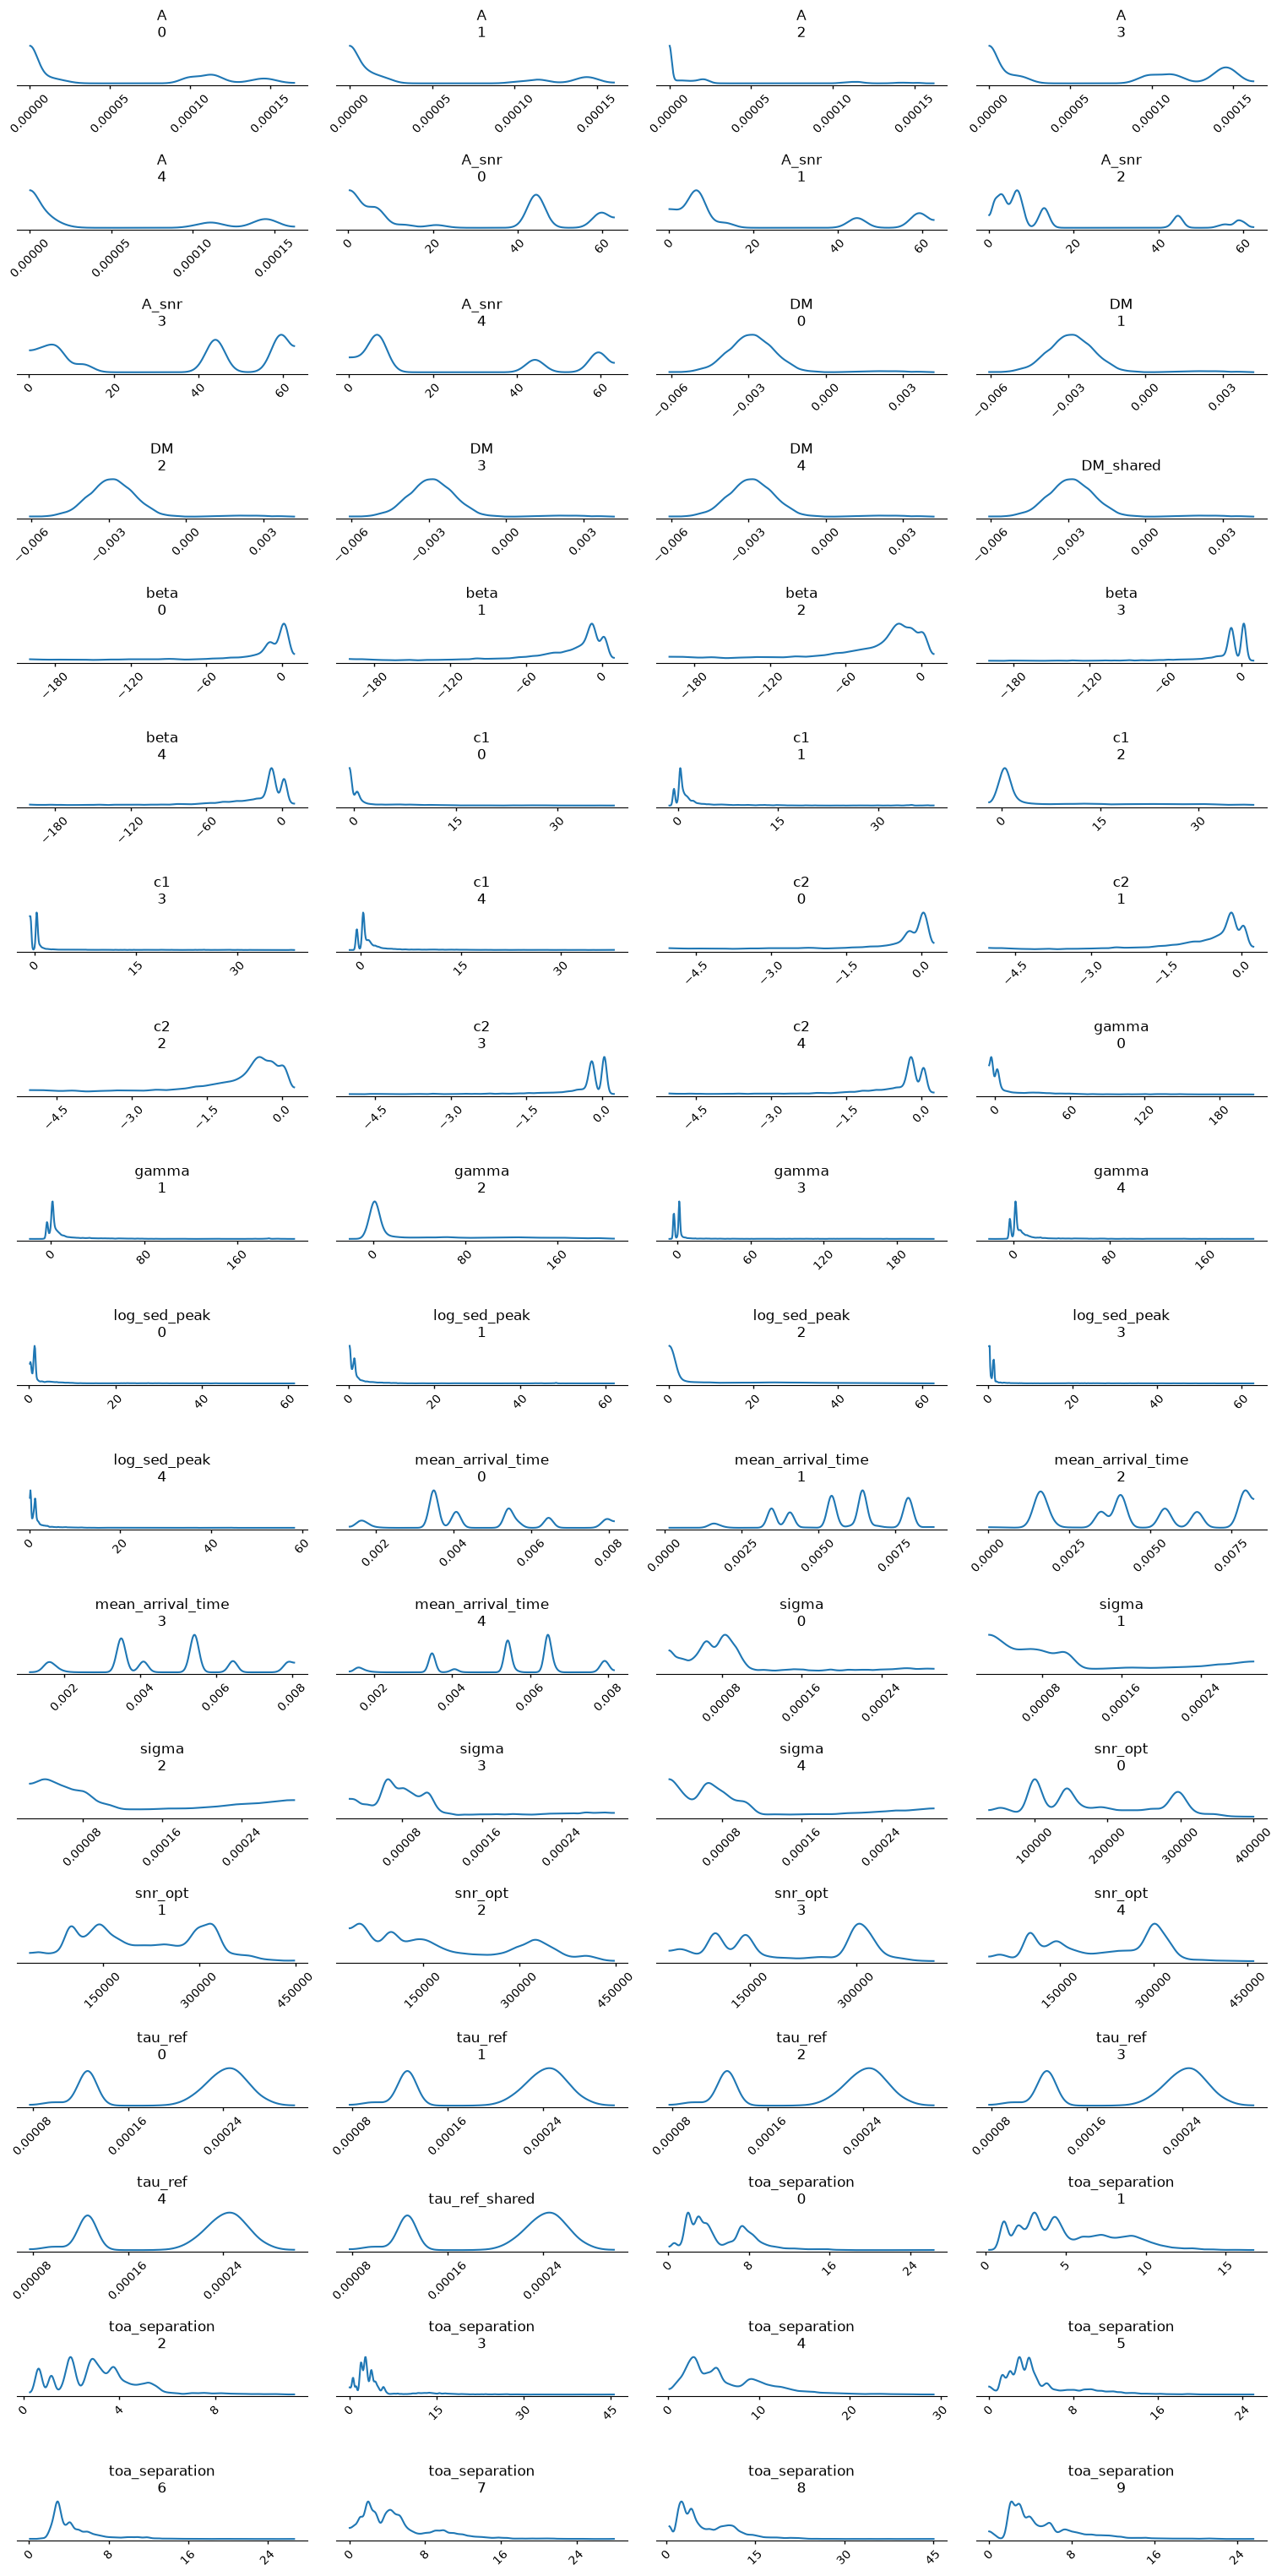

In [12]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

In [13]:
# import warnings

# warnings.filterwarnings(
#     "ignore",
#     message="Explicitly requested dtype.*is not available",
#     category=UserWarning,
# )

# azp.plot_trace(mcmc_data)

# # 2. Clean up x-axis tick clutter across all generated subplots
# for ax in plt.gcf().axes:
#     ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
#     ax.tick_params(axis="x", rotation=45)

# plt.tight_layout()
# plt.show()

In [14]:
pe = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["potential_energy"])
s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
active = s["A_snr"] > 3.0
for c in np.argsort(pe.mean(axis=1)):                      # best (lowest -log post) first
    t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)
    print(f"chain {c}: -log post {pe[c].mean():9.1f} ± {pe[c].std():4.1f}   "
          f"active {active[c].sum(-1).mean():.1f}   t [ms] {np.round(np.sort(t) * 1e3, 2)}   "
          f"A_snr {np.round(np.median(s['A_snr'][c], axis=0), 1)}")

chain 9: -log post    3693.8 ±  4.3   active 4.4   t [ms] [1.64 3.52 4.11 5.45 5.67]   A_snr [20.8 13.5 55.5 42.3  2.7]
chain 2: -log post    3758.9 ±  4.1   active 5.0   t [ms] [3.51 4.09 5.46 6.47 7.97]   A_snr [44.5  6.5 13.2 59.6  7.4]
chain 4: -log post    3759.1 ±  3.5   active 5.0   t [ms] [3.51 4.09 5.46 6.54 7.98]   A_snr [ 6.8 44.7 13.4 59.7  7.3]
chain 6: -log post    3759.2 ±  4.2   active 5.0   t [ms] [3.51 4.09 5.46 6.51 7.97]   A_snr [13.2  7.3  6.8 59.8 44.5]
chain 19: -log post    3773.6 ±  4.3   active 4.6   t [ms] [1.63 3.51 4.09 5.46 6.46]   A_snr [44.  59.1  3.2 12.8  7. ]
chain 10: -log post    3773.6 ±  3.8   active 4.5   t [ms] [1.65 3.51 4.09 5.46 6.46]   A_snr [ 3.2 13.  59.  44.   7.2]
chain 14: -log post    3774.0 ±  3.9   active 4.6   t [ms] [1.65 3.51 4.09 5.46 6.46]   A_snr [ 3.3 59.  12.8 44.   7. ]
chain 29: -log post    3779.8 ±  4.6   active 4.5   t [ms] [1.65 3.51 4.09 5.46 7.97]   A_snr [44.1  6.   3.1 12.9 59.1]
chain 30: -log post    3780.0 ±  4.2

/tmp/ipykernel_15606/2849936320.py:5: RuntimeWarning: All-NaN slice encountered
  t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)


In [15]:
key = jax.random.PRNGKey(6)

  from chain 9
Plotting for Posterior Draw #1982, 5 pulse(s)
A_snr [21.951149  13.911966  56.15519   43.29894    3.9145138]
sigma [6.4357060e-05 4.1060201e-05 6.4731204e-05 1.2058191e-04 1.4088597e-04]
tau_ref [8.688088e-05 8.688088e-05 8.688088e-05 8.688088e-05 8.688088e-05]


/tmp/ipykernel_15606/2477796701.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


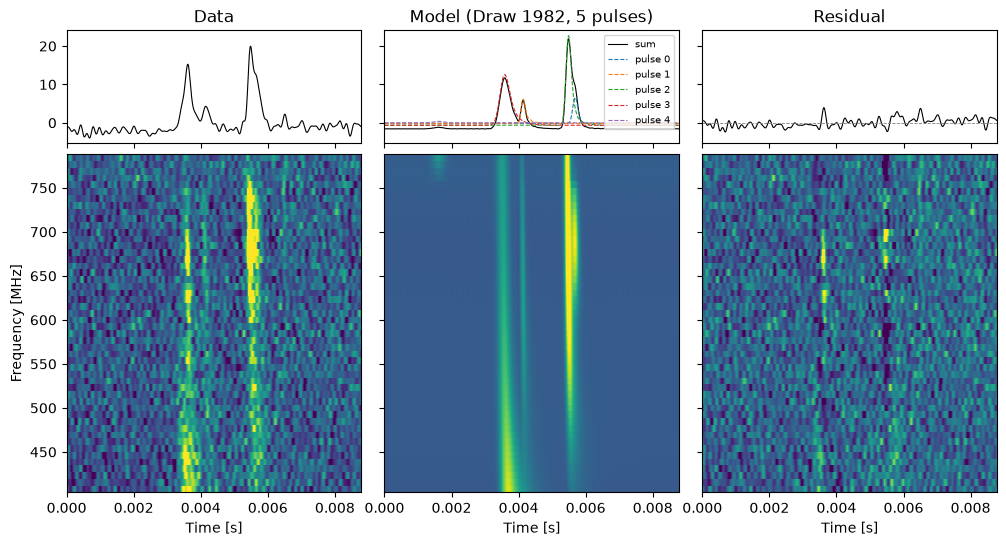

In [23]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = dict(mcmc.get_samples())
# For a marginalized fit, the fluences are not sampled: add the post-hoc draws first, flattened
# to (draws, n_pulses) to match get_samples(), e.g.
#     samples["A"] = extra["A"].reshape(-1, extra["A"].shape[-1])
if "A" not in samples:
    raise KeyError("samples has no 'A'. For a marginalized fit, add the fluences drawn by "
                   "posthoc_samples first (see the comment above).")

num_draws = len(next(iter(samples.values())))
n_pulses = samples["mean_arrival_time"].shape[-1]

# Pick a draw index using JAX random
# key = jax.random.PRNGKey(110)
# key = jax.random.PRNGKey(5)

keep_chains = [9]                                        # the chains to draw from
n_per_chain = num_draws // mcmc.num_chains
allowed = np.concatenate([np.arange(c * n_per_chain, (c + 1) * n_per_chain) for c in keep_chains])
draw_idx = int(allowed[jax.random.randint(key, shape=(), minval=0, maxval=len(allowed))])

# Parameters of the chosen draw, each an array of shape (n_pulses,). Only the parameters the
# model reads are taken; 'A' is the fluence, which single_pulse_fn applies itself.
param_names = [k for k in ("mean_arrival_time", "sigma", "DM", "tau_ref", "c1", "c2",
                           "gamma", "beta", "delta", "A", "A_snr") if k in samples]
test_params = {k: jnp.asarray(samples[k][draw_idx]).reshape(n_pulses) for k in param_names}

print(f"  from chain {draw_idx // n_per_chain}")
print(f"Plotting for Posterior Draw #{draw_idx}, {n_pulses} pulse(s)")
print("A_snr",test_params["A_snr"])
print("sigma",test_params["sigma"])
print("tau_ref",test_params["tau_ref"])

# Evaluate every pulse (vmap over the pulse axis), then sum them for the full model
M_FD_pulses = jax.vmap(single_pulse_fn)(test_params)       # (n_pulses, nfreq, nfourier)
M_FD = jnp.sum(M_FD_pulses, axis=0)                        # (nfreq, nfourier)

# The data and model live on the retained Fourier bins only, so each bin is put back at its own
# index on the full rfft grid before inverting; irfft on the truncated array would reinterpret
# bin k as frequency k / (Nseg dt), which is not where it came from.
Nseg = burst.n_time
dt = burst.dt
n_full = Nseg // 2 + 1
bin_index = jnp.rint(jnp.asarray(burst.fourier_freqs).reshape(-1) * Nseg * dt).astype(int)
pad = lambda X: jnp.zeros(X.shape[:-1] + (n_full,), X.dtype).at[..., bin_index].set(X)

to_TD = lambda X: (1.0 / dt) * jnp.fft.irfft(pad(X), n=Nseg, axis=-1)
M_TD = to_TD(M_FD)
M_TD_pulses = to_TD(M_FD_pulses)                           # (n_pulses, nfreq, ntime)
data_TD = to_TD(burst.data_fd)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = burst.times
freq_plot = jnp.squeeze(burst.freq_channels)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
pulse_ts = jnp.nansum(M_TD_pulses, axis=1)                 # (n_pulses, ntime)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8, label="sum")
if n_pulses > 1:
    # Each component separately, and its arrival time (at the reference frequency)
    colors = plt.cm.tab10(np.arange(n_pulses) % 10)
    t0 = np.asarray(test_params["mean_arrival_time"])
    for j in range(n_pulses):
        ax_ts_model.plot(time_plot, pulse_ts[j], color=colors[j], lw=0.8, ls="--", label=f"pulse {j}")
        # for ax in (ax_ts_model, ax_wf_model):
        #     ax.axvline(t0[j], color=colors[j], lw=0.6, alpha=0.6)
    ax_ts_model.legend(fontsize=7, loc="upper right")
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title(f"Model (Draw {draw_idx}, {n_pulses} pulse{'s' if n_pulses > 1 else ''})")
ax_ts_resid.set_title("Residual")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

In [17]:
P = np.asarray(M_FD_pulses)
inv_var = 1.0 / np.broadcast_to(np.asarray(burst.sigma_noise_fd), burst.data_fd.shape) ** 2
pc = np.sum(np.abs(P) ** 2 * inv_var[None], axis=-1)                    # (n_pulses, n_chan)
nu = np.asarray(fit_fn.grid.normalized_freqs_channels).reshape(-1)       # nu / nu_ref
t0, sig, tau = (np.asarray(test_params[k]).reshape(-1) for k in ("mean_arrival_time", "sigma", "tau_ref"))
for p in range(len(t0)):
    c = np.argmax(pc[p])                                                 # pulse p's brightest channel
    w = np.sqrt(sig ** 2 + (tau * nu[c] ** -4.0) ** 2)
    print(f"pulse {p}'s peak channel (nu/nu_ref = {nu[c]:.2f}): x = {abs(t0[1] - t0[0]) / (w[0] + w[1]):.2f}")

pulse 0's peak channel (nu/nu_ref = 1.40): x = 10.27
pulse 1's peak channel (nu/nu_ref = 1.14): x = 9.57
pulse 2's peak channel (nu/nu_ref = 1.14): x = 9.57
pulse 3's peak channel (nu/nu_ref = 0.73): x = 3.89
pulse 4's peak channel (nu/nu_ref = 1.27): x = 10.06


In [18]:
A = np.asarray(samples["A_snr"]); main = np.argmax(A, axis=1); r = np.arange(len(main))
for name in ("sigma", "tau_ref"):
    v = np.asarray(samples[name]).reshape(len(main), -1)
    v_main = v[r, np.minimum(main, v.shape[1] - 1)]
    hi = np.asarray(priors[name].support.upper_bound)
    print(f"{name}: upper bound {hi}   main pulse 50/99%: {np.percentile(v_main, [50, 99])}")

sigma: upper bound 0.0002928639982201275   main pulse 50/99%: [6.82309401e-05 1.13155519e-04]
tau_ref: upper bound 0.0011637152739660515   main pulse 50/99%: [0.00023284 0.00027927]


In [19]:
print(f"draw {draw_idx}, chain {draw_idx // n_per_chain}")
for p in range(n_pulses):
    print(f"--- pulse {p}")
    for k, v in test_params.items():
        print(f"  {k:18s} {float(np.asarray(v)[p]): .4g}")

draw 2982, chain 14
--- pulse 0
  mean_arrival_time   0.001807
  sigma               0.0002386
  DM                 -0.0005018
  tau_ref             0.0001225
  c1                  28.61
  c2                 -4.82
  gamma               146.3
  beta               -191.3
  A                   1.527e-17
  A_snr               3.288
--- pulse 1
  mean_arrival_time   0.005465
  sigma               0.0001111
  DM                 -0.0005018
  tau_ref             0.0001225
  c1                  0.3153
  c2                 -0.1793
  gamma               1.301
  beta               -7.116
  A                   0.0001434
  A_snr               58.05
--- pulse 2
  mean_arrival_time   0.004092
  sigma               4.78e-05
  DM                 -0.0005018
  tau_ref             0.0001225
  c1                  0.6048
  c2                 -0.516
  gamma               2.071
  beta               -20.48
  A                   1.954e-05
  A_snr               12.7
--- pulse 3
  mean_arrival_time   0.003516
  si

In [20]:
from plotting import model_from_draw, to_time_domain

def local_dominance(draw_idx):
    _, P = model_from_draw(fit_fn, samples, draw_idx)                       # each pulse's model
    inv_var = 1.0 / np.broadcast_to(np.asarray(burst.sigma_noise_fd), burst.data_fd.shape) ** 2
    power = np.sum(np.abs(np.asarray(P)) ** 2 * inv_var[None], axis=-1)     # (n_pulses, n_chan)
    x = np.asarray(to_time_domain(burst, P))                               # (n_pulses, n_chan, n_time)
    x = x - np.median(x, axis=-1, keepdims=True)                           # undo the missing-DC offset
    D = []
    for k in range(x.shape[0]):
        w = power[k] / power[k].sum()                                      # pulse k's own channels
        own = np.tensordot(w, x[k], axes=(0, 0))                           # its profile there
        others = np.tensordot(w, x.sum(axis=0) - x[k], axes=(0, 0))        # everything else, same channels
        t = np.argmax(own)
        D.append(own[t] / max(abs(others[t]), 1e-12))
    return np.array(D)

print(np.round(local_dominance(draw_idx), 2))    # > 1: stands out as a component;  < 1: sits under another pulse

[ 211.09 7260.41   28.44 1947.13  705.58]


In [21]:
def local_dominance(P):
    P = np.asarray(P)
    inv_var = 1.0 / np.broadcast_to(np.asarray(burst.sigma_noise_fd), burst.data_fd.shape) ** 2
    power = np.sum(np.abs(P) ** 2 * inv_var[None], axis=-1)
    x = np.asarray(to_time_domain(burst, P)); x = x - np.median(x, axis=-1, keepdims=True)
    D = []
    for k in range(x.shape[0]):
        w = power[k] / power[k].sum()
        own, others = w @ x[k], w @ (x.sum(0) - x[k])
        t = np.argmax(own); D.append(own[t] / max(abs(others[t]), 1e-12))
    return np.array(D)

D = local_dominance(M_FD_pulses)                  # the plot's own pulses
snr, t0 = np.asarray(test_params["A_snr"]), np.asarray(test_params["mean_arrival_time"])
for k in np.argsort(t0):
    tag = "idle" if snr[k] < 5 else ("component" if D[k] > 1 else "under another pulse")
    print(f"pulse {k}: t = {t0[k]:.6f}  A_snr = {snr[k]:6.1f}  D = {D[k]:8.2f}  -> {tag}")

pulse 0: t = 0.001807  A_snr =    3.3  D =   211.09  -> idle
pulse 3: t = 0.003516  A_snr =   44.4  D =  1947.13  -> component
pulse 2: t = 0.004092  A_snr =   12.7  D =    28.44  -> component
pulse 1: t = 0.005465  A_snr =   58.1  D =  7260.41  -> component
pulse 4: t = 0.006486  A_snr =    8.2  D =   705.58  -> component


In [22]:
print(np.allclose(np.asarray(model_from_draw(fit_fn, samples, draw_idx)[1]), np.asarray(M_FD_pulses)))

flag = []
for i in idx:
    _, P = model_from_draw(fit_fn, samples, int(i))
    snr = np.asarray(samples["A_snr"][int(i)]).reshape(-1)
    flag.append(np.any((snr >= 5.0) & (local_dominance(P) < 1.0)))
print("fraction of draws with a bright pulse under another:", np.mean(flag))

True


NameError: name 'idx' is not defined

In [ ]:
from plotting import model_from_draw
inv_var = 1.0 / np.broadcast_to(np.asarray(burst.sigma_noise_fd), burst.data_fd.shape) ** 2

def dominance(draw_idx):
    _, P = model_from_draw(fit_fn, samples, draw_idx)          # each pulse's model, with its fluence
    P = np.asarray(P)
    G = np.real(np.einsum("jac,kac->jk", P.conj(), P * inv_var[None]))
    S = np.sqrt(np.diag(G))                                      # each pulse's SNR
    Q = G / S[None, :] ** 2                                      # Q[j, k] = G_jk / S_k^2
    np.fill_diagonal(Q, 0.0)
    return S, Q.max(axis=0), Q.argmax(axis=0)                    # for each pulse: largest Q and from which pulse

S, Qmax, by = dominance(draw_idx)
for k in range(len(S)):
    print(f"pulse {k}: SNR {S[k]:6.1f}   max Q {Qmax[k]:6.2f} (from pulse {by[k]})")

In [ ]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
# test_params comes from the posterior-draw cell: each entry has shape (n_pulses,). Every pulse
# is evaluated (vmap over the pulse axis) and the pulses are summed into the full model.
M_FD = jnp.sum(jax.vmap(single_pulse_fn)(test_params), axis=0)     # (nfreq, nfourier)

# The data and the model already live on the truncated Fourier axis, which is exactly the set
# of bins the likelihood uses, so nothing needs slicing here.
data_reshaped_FFT = burst.data_fd
sigma_bins = jnp.broadcast_to(burst.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Re(Model) (Draw {draw_idx})")
ax_ts_data.set_title("Re(Data)")
ax_ts_resid.set_title("Re(Residuals)")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

In [ ]:
n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains

keep_chains = range(mcmc.num_chains)        # or the chains you kept, e.g. [11, 14, 15]
allowed = np.concatenate([np.arange(c * n_per_chain, (c + 1) * n_per_chain) for c in keep_chains])

# A typical draw: random, from the kept chains
draw_idx = int(np.random.default_rng().choice(allowed))
# ...or the single most probable draw (lowest potential energy):
# pe = np.asarray(mcmc.get_extra_fields()["potential_energy"])
# draw_idx = int(allowed[np.argmin(pe[allowed])])
print(f"draw {draw_idx}, chain {draw_idx // n_per_chain}")

M_FD, M_FD_pulses = model_from_draw(single_pulse_fn, samples, draw_idx)

plot_fit_TD(burst, M_FD, M_FD_pulses, title_model=f"Model (draw {draw_idx})");
plot_fit_FD(burst, M_FD, title_model=f"Re(Model) (draw {draw_idx})");